[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tayalmanan28/MuJoCo-Tutorial/blob/main/tutorial/06_xml_modeling.ipynb)

# Tutorial 6: MJCF Modeling Guide

Build custom robots and environments in MuJoCo's XML format.

In [1]:
!pip install -q mujoco mediapy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.8/232.8 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.2/30.2 MB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.5/248.5 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 58.6 MB/s eta 0:00:00


In [2]:
import os
os.environ['MUJOCO_GL'] = 'egl'
import mujoco
import numpy as np
import mediapy as media

In [15]:
print(mujoco.__version__)

3.15.0


## Body-Joint-Geom Hierarchy

MJCF has a tree structure:
```
mujoco
└── worldbody
    └── body (has joints & geoms)
        └── body (child body)
            └── ...
```

- **Bodies** define frames in the kinematic tree
- **Joints** connect bodies (add degrees of freedom)
- **Geoms** define collision/visual shapes

""

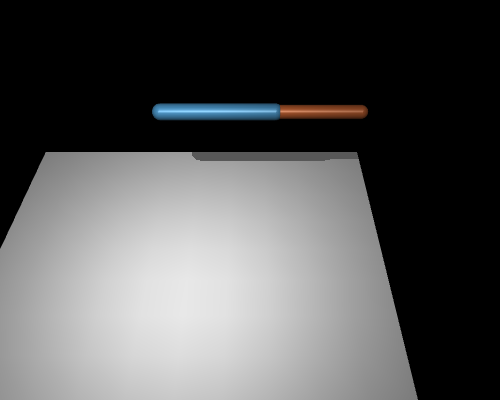

In [3]:
# Build a 2-link arm step by step
arm_xml = """
<mujoco model="2link_arm">
  <option gravity="0 0 -9.81"/>

  <!-- Defaults reduce repetition -->
  <default>
    <joint damping="0.5"/>
    <geom rgba="0.3 0.6 0.8 1"/>
  </default>

  <worldbody>
    <light pos="0 -1 2" dir="0 0.5 -1"/>
    <geom type="plane" size="1 1 0.1" rgba=".9 .9 .9 1"/>

    <!-- Shoulder (fixed to world at height 1) -->
    <body name="upper_arm" pos="0 0 1">
      <joint name="shoulder" type="hinge" axis="0 1 0"/>
      <geom type="capsule" fromto="0 0 0 0.4 0 0" size="0.03"/>

      <!-- Elbow -->
      <body name="forearm" pos="0.4 0 0">
        <joint name="elbow" type="hinge" axis="0 1 0"/>
        <geom type="capsule" fromto="0 0 0 0.3 0 0" size="0.025" rgba="0.8 0.4 0.2 1"/>

        <!-- End-effector marker -->
        <site name="tip" pos="0.3 0 0" size="0.02" rgba="1 0 0 1"/>
      </body>
    </body>
  </worldbody>

  <actuator>
    <motor joint="shoulder" ctrlrange="-5 5"/>
    <motor joint="elbow" ctrlrange="-3 3"/>
  </actuator>
</mujoco>
"""

model = mujoco.MjModel.from_xml_string(arm_xml)
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)

renderer = mujoco.Renderer(model, height=400, width=500)
renderer.update_scene(data)
media.show_image(renderer.render())

## Using Defaults

The `<default>` element lets you set common properties once.
You can also use **default classes** for different groups:

In [4]:
xml_defaults = """
<mujoco>
  <default>
    <default class="visual">
      <geom contype="0" conaffinity="0" group="1"/>
    </default>
    <default class="collision">
      <geom group="0" rgba="1 0 0 0.3"/>
    </default>
  </default>

  <worldbody>
    <light pos="0 0 2"/>
    <body pos="0 0 1">
      <joint type="free"/>
      <!-- Visual geom (detailed mesh appearance) -->
      <geom class="visual" type="box" size="0.2 0.1 0.05" rgba="0.2 0.5 0.8 1"/>
      <!-- Collision geom (simplified shape) -->
      <geom class="collision" type="box" size="0.22 0.12 0.07"/>
    </body>
  </worldbody>
</mujoco>
"""
m = mujoco.MjModel.from_xml_string(xml_defaults)
print(f"Geoms: {m.ngeom} (visual + collision separated via classes)")

Geoms: 2 (visual + collision separated via classes)


## Composite Objects

MuJoCo can auto-generate soft bodies, ropes, and grids:

In [32]:
# ============================================================
# 1. 创建 MuJoCo 绳索模型
# ============================================================

rope_xml = """
<mujoco model="hanging_rope">

  <!-- 重力沿 Z 轴负方向，仿真步长 0.002 秒 -->
  <option gravity="0 0 -9.81"/>

  <!-- 注册绳索弹性插件 -->
  <extension>
    <plugin plugin="mujoco.elasticity.cable"/>
  </extension>

  <worldbody>

    <!-- 光源 -->
    <light pos="0 0 2" dir="0 0 -1"/>

    <!-- 地面 -->
    <geom name="floor"
          type="plane"
          pos="0 0 0"
          size="2 2 0.1"
          rgba="0.85 0.85 0.85 1"/>

    <!-- 上端固定的绳索 -->
    <composite
    prefix="rope"
    type="cable"
    curve="s 0 0"
    count="31 1 1"
    size="-0.8 0 0"
    offset="0 0 1.5"
    initial="none">

  <plugin plugin="mujoco.elasticity.cable">
    <config key="twist" value="1000"/>
    <config key="bend" value="1000"/>
  </plugin>

  <joint kind="main" damping="0.02" armature="0.001"/>
  <geom type="capsule" size="0.05" rgba="0.8 0.2 0.1 1" density="1000"/>
</composite>

  </worldbody>
</mujoco>
"""

# ============================================================
# 2. 编译模型并初始化仿真
# ============================================================

model = mujoco.MjModel.from_xml_string(rope_xml)
data = mujoco.MjData(model)

print("模型编译成功")
print("自由度数量：", model.nv)

# ============================================================
# 3. 设置渲染器
# ============================================================

renderer = mujoco.Renderer(
    model,
    height=480,
    width=640
)

# ============================================================
# 4. 执行仿真并采集视频帧
# ============================================================

simulation_time = 5.0
fps = 30

total_steps = int(simulation_time / model.opt.timestep)
steps_per_frame = max(
    1,
    round(1.0 / (fps * model.opt.timestep))
)

frames = []

for step in range(total_steps):

    # 推进一个仿真步
    mujoco.mj_step(model, data)

    # 定期渲染并保存图像
    if step % steps_per_frame == 0:
        renderer.update_scene(data)
        frames.append(renderer.render().copy())

# 释放渲染器资源
renderer.close()

# ============================================================
# 5. 播放仿真视频
# ============================================================

print("仿真结束，视频帧数：", len(frames))

media.show_video(frames, fps=fps)

模型编译成功
自由度数量： 87
仿真结束，视频帧数： 148


This browser does not support the video tag.


In [17]:
rope_xml = """
<mujoco>
  <option gravity="0 0 -9.81"/>
  <worldbody>
    <light pos="0 0 2"/>
    <geom type="plane" size="2 2 0.1" rgba=".9 .9 .9 1"/>

    <composite type="cable" count="15 1 1" offset="0 0 1">
      <joint kind="main" damping="0.01"/>
      <geom type="capsule" size=".01 .015" rgba="0.8 0.2 0.1 1"/>
    </composite>
  </worldbody>
</mujoco>
"""

model_r = mujoco.MjModel.from_xml_string(rope_xml)
data_r = mujoco.MjData(model_r)
renderer_r = mujoco.Renderer(model_r, height=400, width=500)

frames = []
while data_r.time < 3.0:
    mujoco.mj_step(model_r, data_r)
    if len(frames) < data_r.time * 30:
        renderer_r.update_scene(data_r)
        frames.append(renderer_r.render().copy())

renderer_r.close()
media.show_video(frames, fps=30)

ValueError: Error: fromto points too close in geom
Element name 'G0', id 1

## Loading External Models

Use `<include>` to compose models, or load from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie):

""

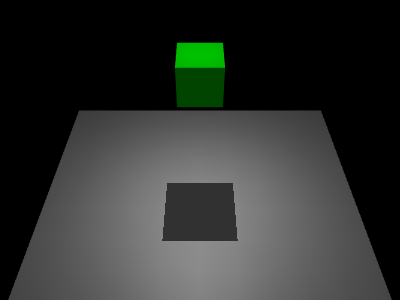

Model created programmatically with MjSpec!


In [33]:
# Example: programmatic model editing (MuJoCo 3.x spec API)
spec = mujoco.MjSpec()
spec.worldbody.add_light(pos=[0, 0, 2])
spec.worldbody.add_geom(type=mujoco.mjtGeom.mjGEOM_PLANE, size=[1, 1, 0.1])

body = spec.worldbody.add_body(name='dynamic_box', pos=[0, 0, 1])
body.add_joint(type=mujoco.mjtJoint.mjJNT_FREE)
body.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.1, 0.1, 0.1], mass=1.0, rgba=[0, 0.7, 0, 1])

model_spec = spec.compile()
data_spec = mujoco.MjData(model_spec)
mujoco.mj_forward(model_spec, data_spec)

renderer_s = mujoco.Renderer(model_spec, height=300, width=400)
renderer_s.update_scene(data_spec)
media.show_image(renderer_s.render())
renderer_s.close()
print("Model created programmatically with MjSpec!")

## Tendons

Tendons are length constraints that connect joints or spatial points.
They enable **coupled joints**, **pulleys**, and **muscle routing**.

Types:
- `<fixed>` — weighted sum of joint positions (coupling)
- `<spatial>` — routes through via-points and wrapping surfaces

This browser does not support the video tag.


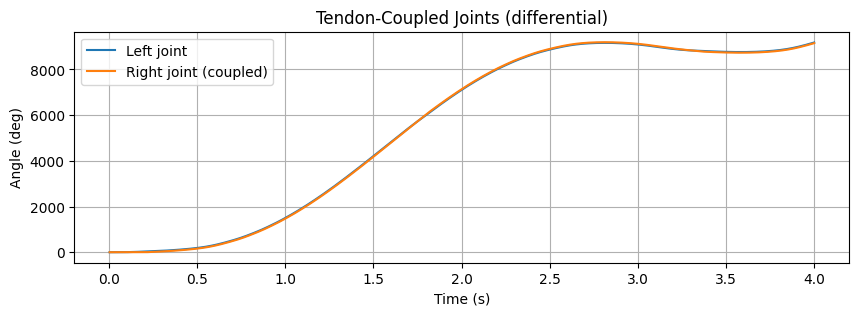

The tendon forces the joints to move in opposite directions!


In [36]:
import matplotlib.pyplot as plt
xml_tendon = """
<mujoco>
  <option gravity="0 0 -9.81"/>
  <worldbody>
    <light pos="0 0 2"/>
    <geom type="plane" size="1 1 0.1" rgba=".9 .9 .9 1"/>

    <!-- Two joints coupled by a tendon (like a differential) -->
    <body pos="-0.2 0 0.5">
      <joint name="left" type="hinge" axis="0 1 0"/>
      <geom type="capsule" fromto="0 0 0 0 0 -0.3" size="0.02" rgba="0.8 0.2 0.2 1"/>
    </body>
    <body pos="0.2 0 0.5">
      <joint name="right" type="hinge" axis="0 1 0"/>
      <geom type="capsule" fromto="0 0 0 0 0 -0.3" size="0.02" rgba="0.2 0.2 0.8 1"/>
    </body>
  </worldbody>

  <!-- Fixed tendon: couples left and right joints -->
  <!-- coef=1 for left, coef=-1 for right means they move opposite -->
  <tendon>
    <fixed name="coupled" limited="true" range="-0.5 0.5">
      <joint joint="left" coef="1"/>
      <joint joint="right" coef="-1"/>
    </fixed>
  </tendon>

  <actuator>
    <motor joint="left" ctrlrange="-5 5"/>
  </actuator>
</mujoco>
"""

model_t = mujoco.MjModel.from_xml_string(xml_tendon)
data_t = mujoco.MjData(model_t)
renderer = mujoco.Renderer(model_t,height=480,width=600)
frames = []
fps = 60

# Drive left joint — right joint follows (opposite direction)
times, left_angles, right_angles = [], [], []
while data_t.time < 4.0:
    data_t.ctrl[0] = 3.0 * np.sin(2 * data_t.time)
    mujoco.mj_step(model_t, data_t)
    times.append(data_t.time)
    left_angles.append(np.degrees(data_t.qpos[0]))
    right_angles.append(np.degrees(data_t.qpos[1]))
    renderer.update_scene(data_t)
    frames.append(renderer.render().copy())

renderer.close()
media.show_video(frames,fps=fps)

plt.figure(figsize=(10, 3))
plt.plot(times, left_angles, label='Left joint')
plt.plot(times, right_angles, label='Right joint (coupled)')
plt.xlabel('Time (s)'); plt.ylabel('Angle (deg)')
plt.title('Tendon-Coupled Joints (differential)'); plt.legend(); plt.grid(True); plt.show()
print('The tendon forces the joints to move in opposite directions!')

## Equality Constraints

Equality constraints enforce geometric relationships:

| Type | Effect |
|------|--------|
| `<connect>` | Two bodies share a point (ball joint without a body) |
| `<weld>` | Two bodies are rigidly attached |
| `<joint>` | One joint follows another (gear ratio) |
| `<tendon>` | Tendon length is fixed |

These are soft constraints (solved with impedance), controlled by `solref` and `solimp`.

This browser does not support the video tag.


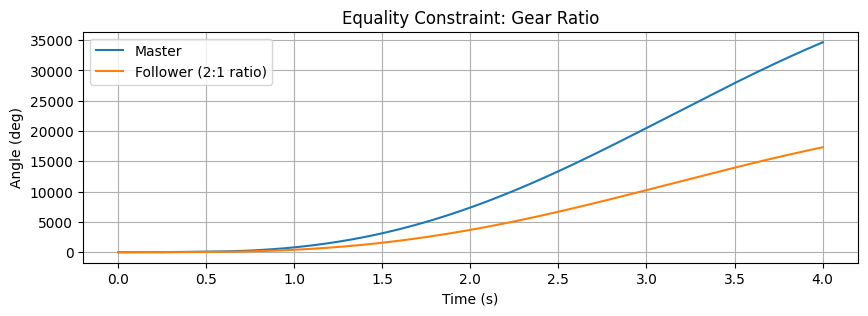

Follower moves at 2x the master angle — like a gear train!


In [38]:
xml_equality = """
<mujoco>
  <option gravity="0 0 -9.81"/>
  <worldbody>
    <light pos="0 0 3"/>
    <geom type="plane" size="1 1 0.1" rgba=".9 .9 .9 1"/>

    <!-- Master joint (actuated) -->
    <body name="master" pos="-0.3 0 0.5">
      <joint name="j_master" type="hinge" axis="0 1 0"/>
      <geom type="capsule" fromto="0 0 0 0 0 -0.3" size="0.025" rgba="0.2 0.7 0.3 1"/>
    </body>

    <!-- Follower joint (2:1 gear ratio) -->
    <body name="follower" pos="0.3 0 0.5">
      <joint name="j_follower" type="hinge" axis="0 1 0"/>
      <geom type="capsule" fromto="0 0 0 0 0 -0.2" size="0.02" rgba="0.7 0.3 0.2 1"/>
    </body>
  </worldbody>

  <!-- Follower moves at 2x the speed of master -->
  <equality>
    <joint joint1="j_master" joint2="j_follower" polycoef="0 2 0 0 0"/>
  </equality>

  <actuator>
    <motor joint="j_master" ctrlrange="-5 5"/>
  </actuator>
</mujoco>
"""

model_eq = mujoco.MjModel.from_xml_string(xml_equality)
data_eq = mujoco.MjData(model_eq)
renderer = mujoco.Renderer(model_eq,height=480,width=600)
frames = []
fps = 60

times, master_angles, follower_angles = [], [], []
while data_eq.time < 4.0:
    data_eq.ctrl[0] = 3.0 * np.sin(data_eq.time)
    mujoco.mj_step(model_eq, data_eq)
    times.append(data_eq.time)
    master_angles.append(np.degrees(data_eq.qpos[0]))
    follower_angles.append(np.degrees(data_eq.qpos[1]))
    renderer.update_scene(data_eq)
    frames.append(renderer.render().copy())

renderer.close()
media.show_video(frames,fps=fps)

plt.figure(figsize=(10, 3))
plt.plot(times, master_angles, label='Master')
plt.plot(times, follower_angles, label='Follower (2:1 ratio)')
plt.xlabel('Time (s)'); plt.ylabel('Angle (deg)')
plt.title('Equality Constraint: Gear Ratio'); plt.legend(); plt.grid(True); plt.show()
print('Follower moves at 2x the master angle — like a gear train!')